# Final results figure panels

This notebook uses the exported `ground_truth.csv` and `model.csv` files. It creates separate Familiar and Novel B panels, the sector grouped C panel, and an Appendix C version with three additional model ablation columns. The existing vector and cosine plotting functions are used unchanged for D and E.

Trace ribbons show ±1 sample SD by default: across neurons for data and across seeds for model, after averaging repeated images within each replicate. D ellipses show ±1 SD across neuron/seed transition vectors. E point plot error bars show ±1 SD across empirical neuron-level cosine values. The transition proportions are descriptive sample fractions, shown with their percentages.

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, display

cwd = Path.cwd().resolve()
PAPER_DIR = cwd / "paper_v2" if (cwd / "paper_v2" / "plot.py").exists() else cwd
REPO_DIR = PAPER_DIR.parent
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from paper_v2 import plot

plot.use_myriad_pro()
import pandas as pd
DATA = pd.read_csv(PAPER_DIR / "ground_truth.csv")
MODEL = pd.read_csv(PAPER_DIR / "model.csv")
PLOTTED_DATA = DATA.loc[~DATA.sector.eq("-O axis")]
OUT = PAPER_DIR / "figures" / "final_layout"
OUT.mkdir(parents=True, exist_ok=True)
FONT_SIZE = 12
UNCERTAINTY = "sem"

## Panel B — Familiar

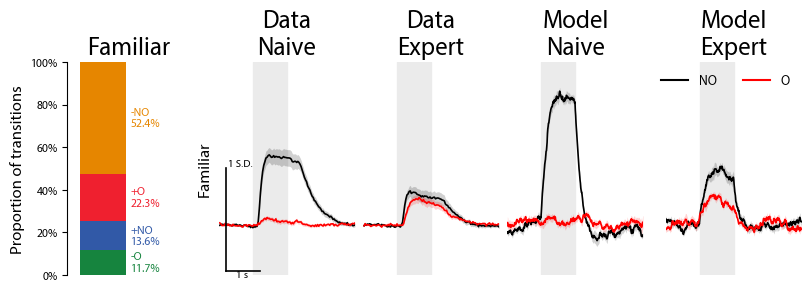

In [2]:
fig, axes = plot.panel_b(DATA, MODEL, source="familiar", width=8, height=2.8,
                            fontsize=FONT_SIZE, uncertainty=UNCERTAINTY)
display(fig)
plot.save(fig, OUT / "panel_B_familiar")

### Familiar transition proportions (standalone export)

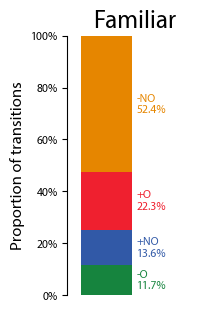

In [3]:
fig, ax = plot.panel_b_proportions(DATA, source="familiar", width=2, height=3,
                                       fontsize=FONT_SIZE)
display(fig)
plot.save(fig, OUT / "panel_B_familiar_proportions")

## Panel B — Novel

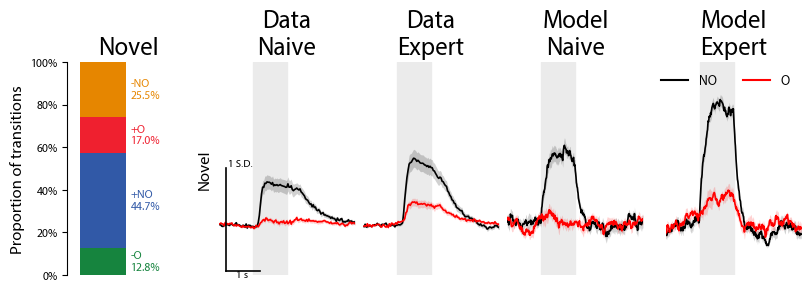

In [4]:
fig, axes = plot.panel_b(DATA, MODEL, source="novel", width=8, height=2.8,
                            fontsize=FONT_SIZE, uncertainty=UNCERTAINTY)
display(fig)
plot.save(fig, OUT / "panel_B_novel")

### Novel transition proportions (standalone export)

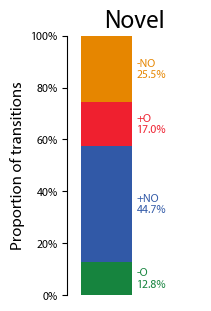

In [5]:
fig, ax = plot.panel_b_proportions(DATA, source="novel", width=2, height=3,
                                       fontsize=FONT_SIZE)
display(fig)
plot.save(fig, OUT / "panel_B_novel_proportions")

## Panel C — sector grouped traces

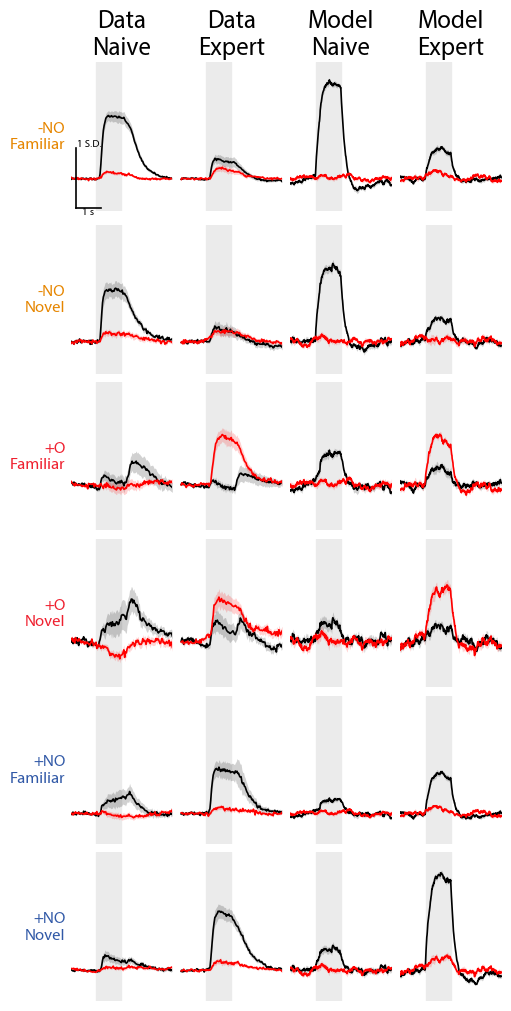

In [6]:
fig, axes = plot.panel_c(DATA, MODEL, width=5, height=10, fontsize=FONT_SIZE,
                            uncertainty=UNCERTAINTY)
display(fig)
plot.save(fig, OUT / "panel_C")

## Appendix C — Panel C plus three model ablation columns

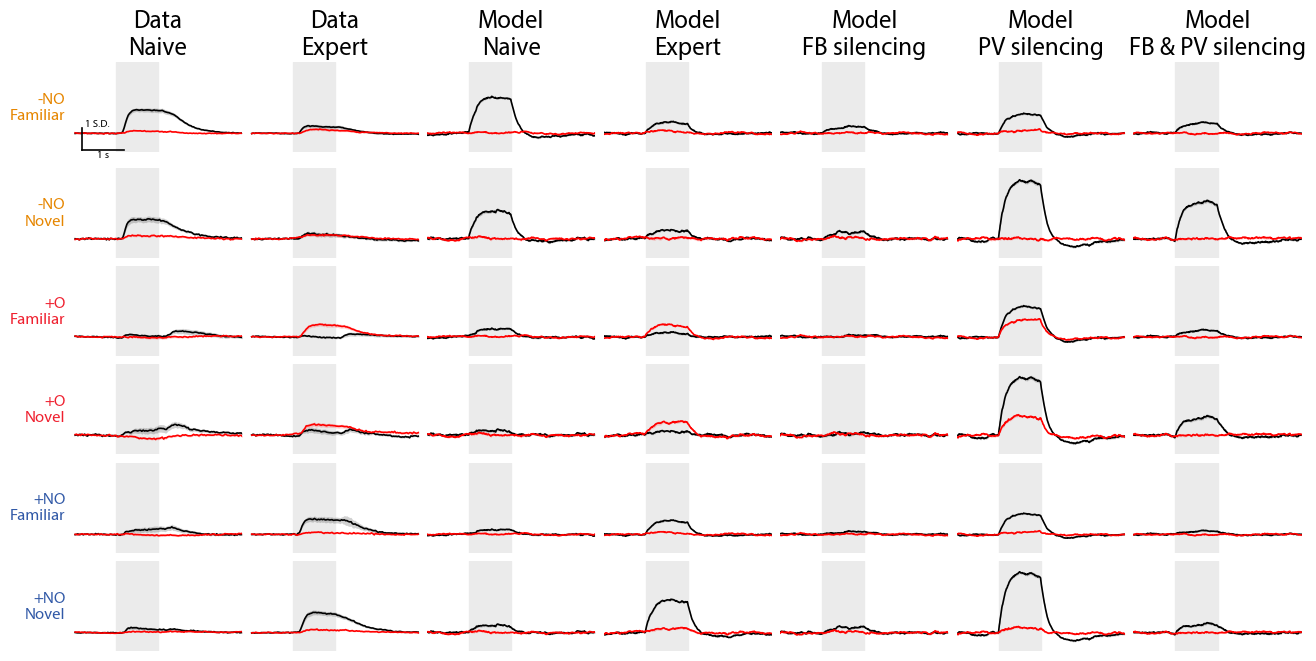

In [7]:
fig, axes = plot.panel_c_appendix(DATA, MODEL, width=13, height=6.5, fontsize=FONT_SIZE,
                                     uncertainty=UNCERTAINTY, model_only=False)
display(fig)
plot.save(fig, OUT / "appendix_C")

## Panel D — existing transition vector plots

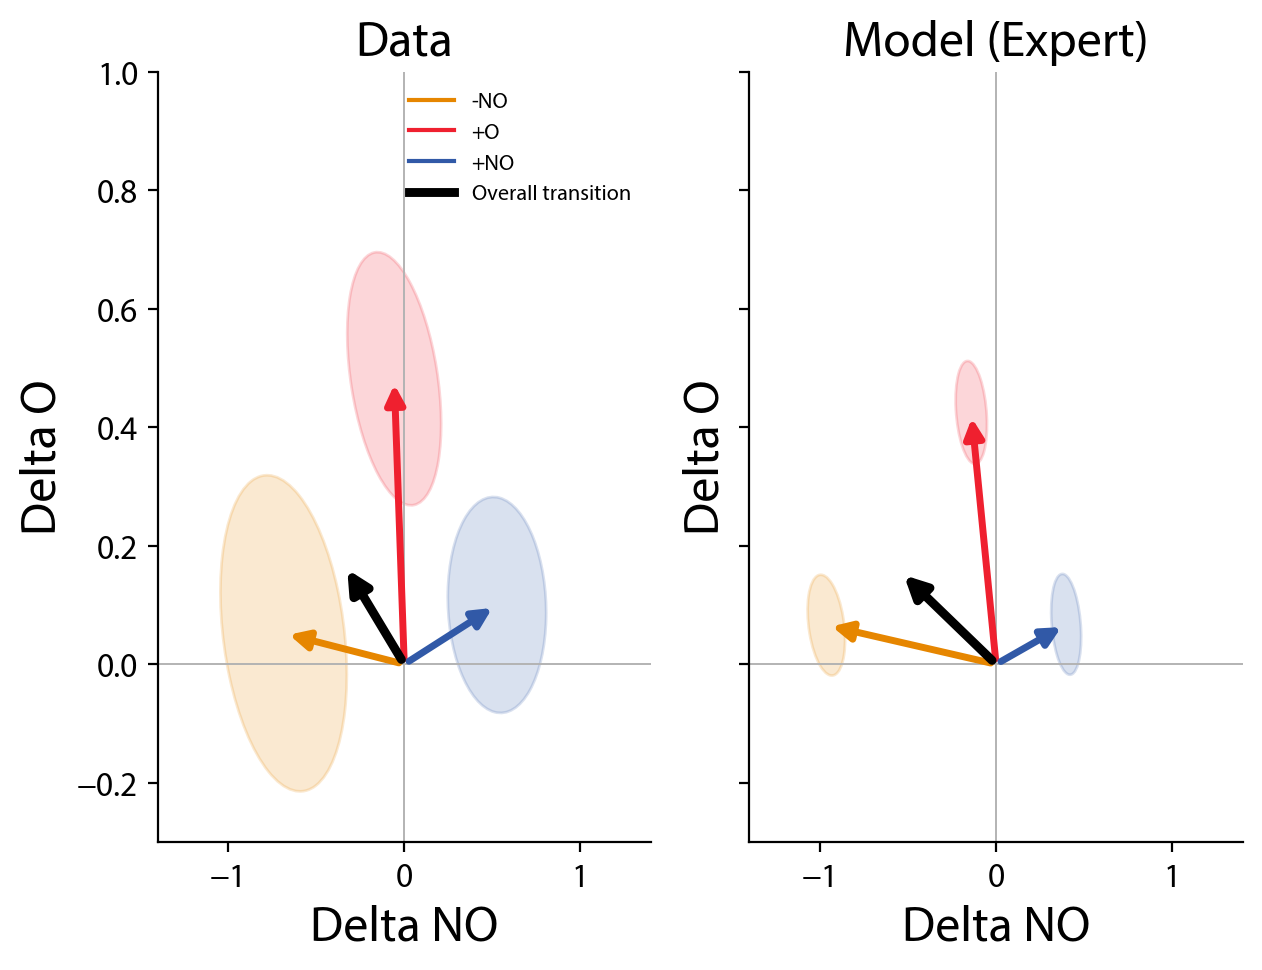

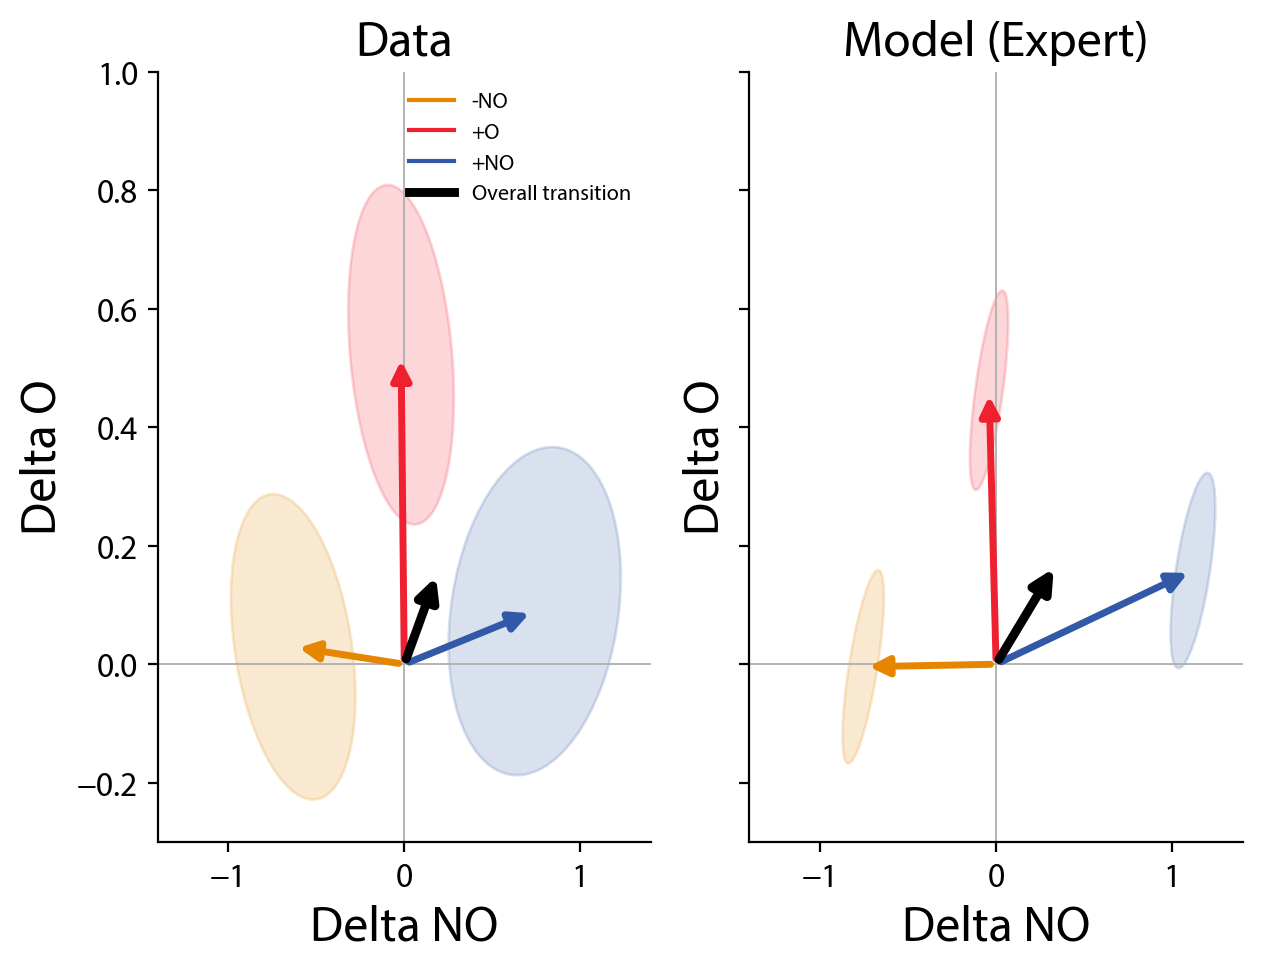

In [8]:
plot.plot_vectors(PLOTTED_DATA, MODEL, "familiar", OUT / "panel_D_familiar",
                  uncertainty='sd', condition="expert")
plot.plot_vectors(PLOTTED_DATA, MODEL, "novel", OUT / "panel_D_novel",
                  uncertainty='sd', condition="expert")
display(Image(filename=OUT / "panel_D_familiar.png"))
display(Image(filename=OUT / "panel_D_novel.png"))

## Panel E — existing cosine similarity plots

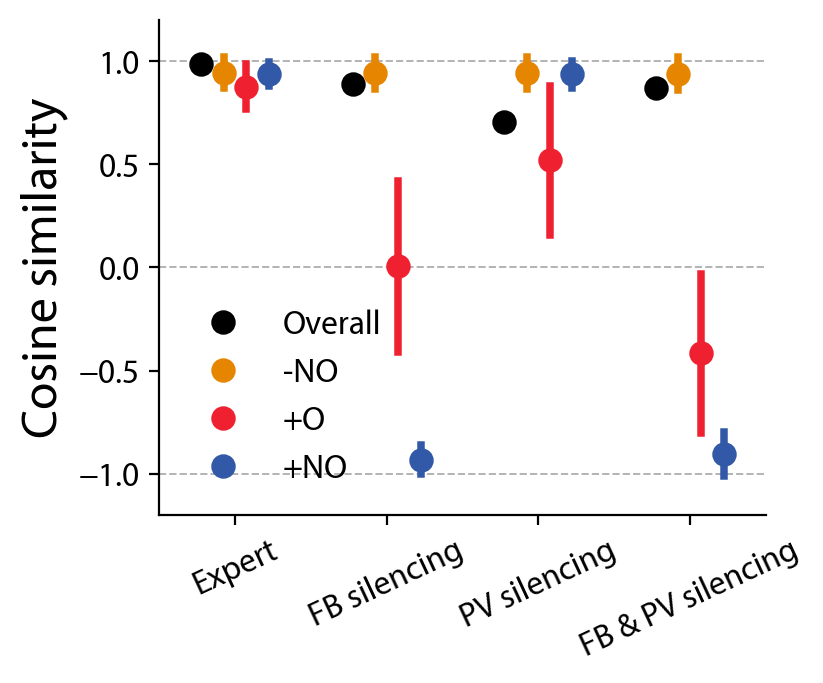

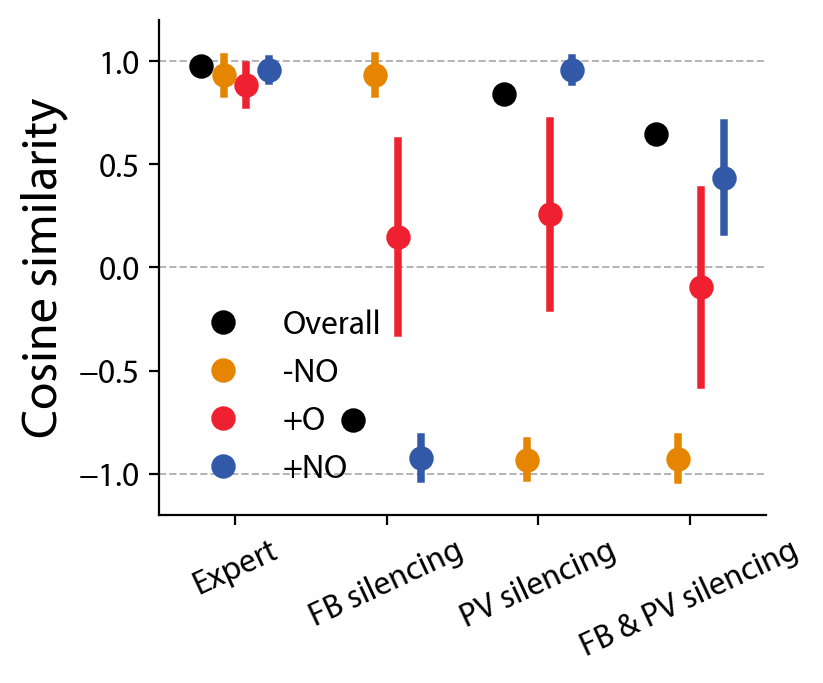

In [9]:
plot.plot_similarities(PLOTTED_DATA, MODEL, "familiar", OUT / "panel_E_familiar_cosine",
                       errorbars=True, #uncertainty=('se', 2)
                       )
plot.plot_similarities(PLOTTED_DATA, MODEL, "novel", OUT / "panel_E_novel_cosine",
                       errorbars=True, #uncertainty=('se', 2)
                       )
display(Image(filename=OUT / "panel_E_familiar_cosine.png"))
display(Image(filename=OUT / "panel_E_novel_cosine.png"))

The panel B/C plotting functions accept dimensions in inches and a font size. Existing D and E plotting functions retain their prior plot sizes, axes, and calculations. All files are saved as PNG and SVG under `figures/final_layout/`.

## Robustness summary — perturbation range (0.05x–5x) over which each transition stays in its sector with ≥25% of original amplitude

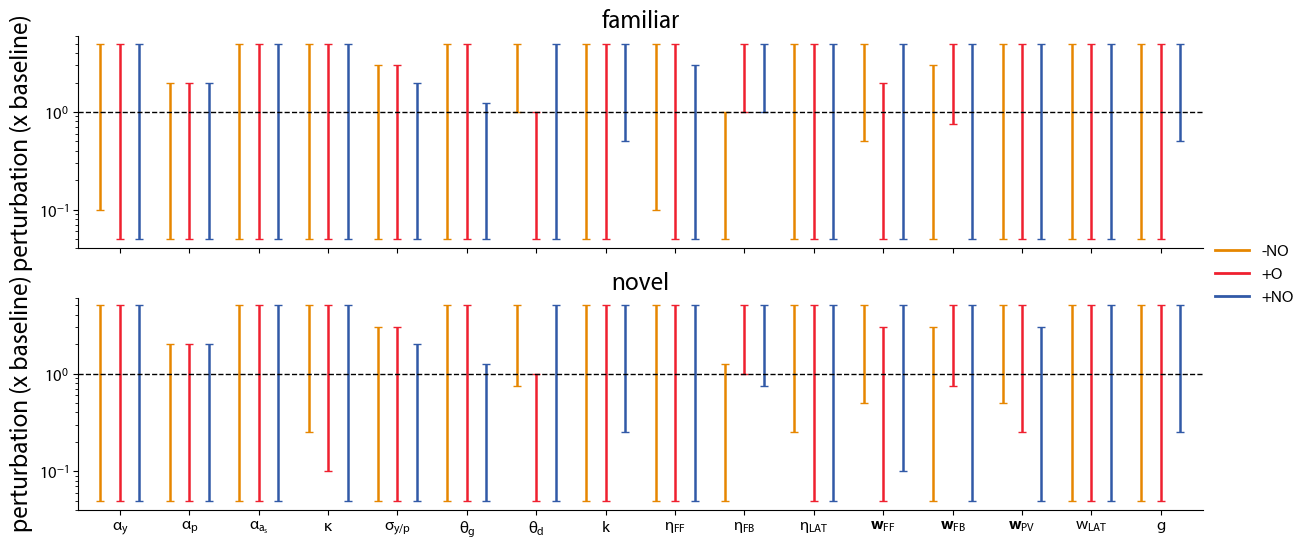

In [10]:
import yaml
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns

LABELS = {"pyc_decay": r"$\alpha_y$", "pv_decay": r"$\alpha_p$", "ff_accumulator_alpha_factor": r"$\alpha_{a_s}$",
          "divisive_gain": r"$\kappa$", "baseline_drive_sigma": r"$\sigma_{y/p}$", "apical_gain_threshold": r"$\theta_g$",
          "apical_drive_threshold": r"$\theta_d$", "apical_gain_k": r"$k$", "lr_ff": r"$\eta_{FF}$",
          "lr_fb": r"$\eta_{FB}$", "lr_lat": r"$\eta_{LAT}$", "w_ff": r"$\mathbf{w}_{FF}$", "w_fb": r"$\mathbf{w}_{FB}$",
          "W_pv": r"$\mathbf{w}_{PV}$", "w_lat": r"$w_{LAT}$", "apical_gain_strength": r"$g$"}
# math labels in Myriad Pro too (default mathtext uses DejaVu)
plt.rcParams.update({"mathtext.fontset": "custom", "mathtext.rm": "Myriad Pro", "mathtext.it": "Myriad Pro:italic", "mathtext.bf": "Myriad Pro:bold"})
DODGE, HEIGHT, ASPECT = 0.28, 2.8, 4.2   # offset between sectors, row height, row width/height

rob = pd.read_csv("robustness/results.csv")
base = {c["id"]: c["parameters"] for c in yaml.safe_load(open("robustness/config.yaml"))["cells"]}
rob = rob[rob.kind.isin(["family", "scalar"]) & rob.parameter.isin(LABELS)].copy()
rob["factor"] = [(v if k == "family" else v / base[c][p]) for k, v, c, p in zip(rob.kind, rob.value, rob.cell_id, rob.parameter)]
rob["factor"] = rob.factor.round(3)

def robust_range(s):  # contiguous multipliers around 1x that stay in sector with >=25% of the original amplitude
    f = s.index.to_numpy(float); i = int(np.argmin(abs(f - 1))); lo = hi = i
    while lo > 0 and s.iloc[lo - 1]: lo -= 1
    while hi < len(s) - 1 and s.iloc[hi + 1]: hi += 1
    return f[lo], f[hi]

ok = rob.groupby(["source", "sector", "parameter", "factor"]).retained.all()
rows = [(src, sec, p, *robust_range(ok[src, sec, p])) for src in ["familiar", "novel"] for sec in plot.SECTORS for p in LABELS]
rng = pd.DataFrame(rows, columns=["source", "sector", "parameter", "lo", "hi"])
rng["label"] = rng.parameter.map(LABELS); rng["x"] = rng.parameter.map({p: i for i, p in enumerate(LABELS)})
rng["sector"] = rng.sector.map(plot.SECTOR_SHORT)
rng["width"] = np.log10(rng.hi / rng.lo)   # decades; the full 0.05-5x range is 2
PALETTE = {plot.SECTOR_SHORT[s]: c for s, c in plot.COLORS.items()}
HUE = [plot.SECTOR_SHORT[s] for s in plot.SECTORS]
TICKS = dict(ticks=range(len(LABELS)), labels=list(LABELS.values()))

def draw_ranges(data, **kw):
    ax = plt.gca()
    for j, sector in enumerate(HUE):
        d = data[data.sector == sector]
        ax.errorbar(d.x + (j - 1) * DODGE, d.lo, yerr=[np.zeros(len(d)), d.hi - d.lo], fmt="none", capsize=3, lw=1.8, color=PALETTE[sector], label=sector)

g = sns.FacetGrid(rng, row="source", height=HEIGHT, aspect=ASPECT, sharey=True, sharex=True)
g.map_dataframe(draw_ranges)
g.set(yscale="log", ylim=(0.04, 6), xlim=(-0.6, len(LABELS) - 0.4), ylabel="perturbation (x baseline)", xlabel="")
for ax in g.axes.flat: ax.axhline(1, color="k", ls="--", lw=1)
g.axes[-1, 0].set_xticks(**TICKS)
g.set_titles("{row_name}"); sns.despine(g.figure)
g.add_legend(handles=[plt.Line2D([], [], color=PALETTE[s], lw=2, label=s) for s in HUE], title="")
plt.show()
plot.save(g.figure, OUT / "robustness_summary")


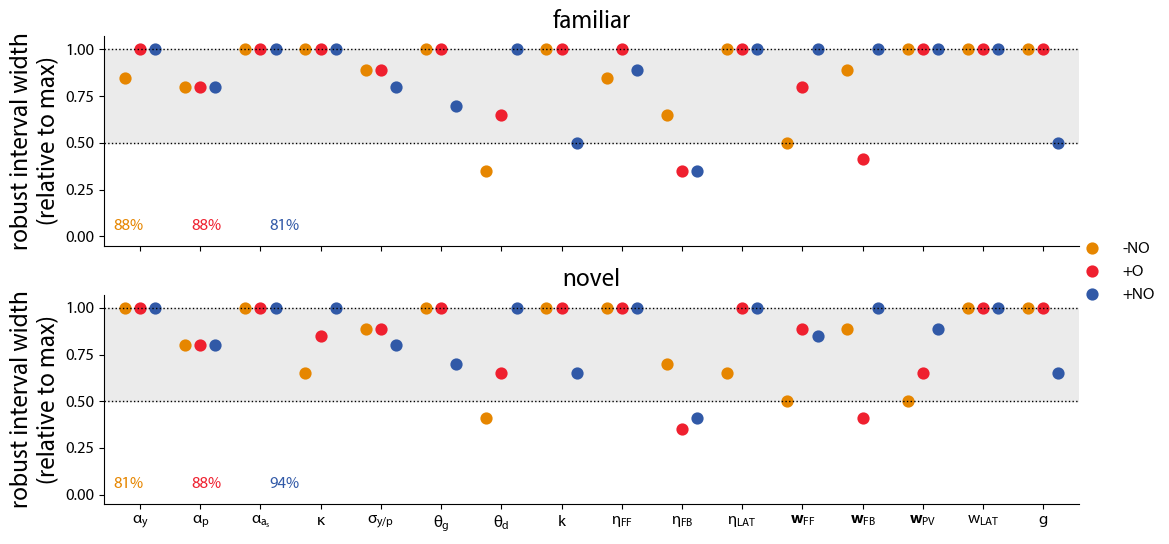

In [11]:
# width of each robust interval relative to the maximum (log10 hi/lo, divided by the 2 decades of 0.05-5x); reuses `rng`, `PALETTE`, `HUE`, `TICKS`, `HEIGHT`, `ASPECT`, `DODGE` from the cell above
rng["rel_width"] = rng.width / 2
wide = rng.groupby(["source", "sector"]).rel_width.apply(lambda w: (w > 0.5).mean())
fig, axes = plt.subplots(2, 1, figsize=(HEIGHT * ASPECT, 2 * HEIGHT), sharex=True, sharey=True)
for ax, source in zip(axes, ["familiar", "novel"]):
    sns.pointplot(rng[rng.source == source], x="x", y="rel_width", hue="sector", hue_order=HUE, palette=PALETTE, dodge=DODGE * 1.8,
                  linestyle="none", markers="o", errorbar=None, native_scale=True, ax=ax)
    ax.axhline(1, color="k", ls=":", lw=1); ax.axhline(0.5, color="k", ls=":", lw=1)
    ax.axhspan(0.5, 1, color="0.92", zorder=0)
    for j, sector in enumerate(HUE):   # share of parameters whose robust width exceeds half the maximum
        ax.text(0.01 + 0.08 * j, 0.06, f"{wide[source, sector]:.0%}", transform=ax.transAxes, color=PALETTE[sector], ha="left", va="bottom")   # max width and 50% of it
    ax.set_ylim(-0.05, 1.07); ax.set_yticks([0, 0.25, 0.5, 0.75, 1]); ax.set_title(source); ax.set_xlabel(""); ax.set_ylabel("robust interval width\n(relative to max)")
    ax.set_xlim(-0.6, len(LABELS) - 0.4); ax.legend_.remove()
axes[-1].set_xticks(**TICKS)
fig.legend(*axes[0].get_legend_handles_labels(), loc="center right", frameon=False)
fig.tight_layout(rect=(0, 0, 0.94, 1))
sns.despine(fig)
plt.show()
plot.save(fig, OUT / "robustness_width")


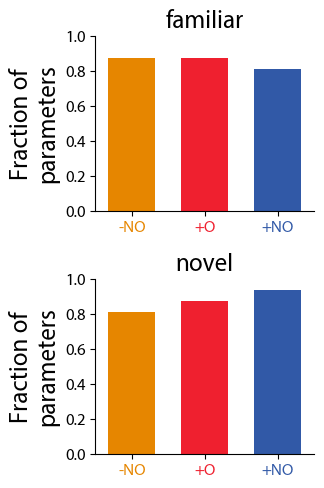

In [12]:
# fraction of parameters whose robust width exceeds 0.5 of the maximum; reuses `rng`, `PALETTE`, `HUE`, `HEIGHT`
frac = rng.assign(wide=rng.rel_width > 0.5).groupby(["source", "sector"]).wide.mean().reset_index()
fig, axes = plt.subplots(2, 1, figsize=(3.4, 2 * HEIGHT * 0.9), sharex=True, sharey=True)
for ax, source in zip(axes, ["familiar", "novel"]):
    sns.barplot(frac[frac.source == source], x="sector", y="wide", order=HUE, palette=PALETTE, hue="sector", hue_order=HUE, legend=False, width=0.65, saturation=1, ax=ax)
    ax.set(ylim=(0, 1), title=source, xlabel="", ylabel="Fraction of\nparameters")
for ax, source in zip(axes, ["familiar", "novel"]): ax.xaxis.set_tick_params(labelbottom=True)
for ax in axes:
    for lab in ax.get_xticklabels(): lab.set_color(PALETTE[lab.get_text()])
sns.despine(fig)
fig.tight_layout()
plt.show()
plot.save(fig, OUT / "robustness_width_summary")
